# Stock price and risk report
**SHUBHAM GUPTA**

Returns and risk calculations use adjusted closes. All prices come from the
cleaned SQLite table. No dividends are added separately.

In [1]:
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [3]:
import math
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
start = pd.Timestamp(start_date)
end = pd.Timestamp(end_date)
if start > end:
    raise ValueError("start_date must be on or before end_date")
database = Path(db_path)
if not database.is_file():
    raise FileNotFoundError(database)
with sqlite3.connect(f"{database.resolve().as_uri()}?mode=ro", uri=True) as con:
    dates = pd.read_sql_query(
        "SELECT DISTINCT ts FROM ohlc_hw_cleaned WHERE ts <= ? ORDER BY ts",
        con, params=(end.strftime("%Y-%m-%d"),)
    )
    quotes = pd.read_sql_query(
        "SELECT ts, adj_close FROM ohlc_hw_cleaned "
        "WHERE ticker = ? AND ts <= ? ORDER BY ts",
        con, params=(ticker, end.strftime("%Y-%m-%d"))
    )
calendar = pd.DatetimeIndex(pd.to_datetime(dates.ts))
quotes["ts"] = pd.to_datetime(quotes.ts)
price = quotes.set_index("ts").adj_close.reindex(calendar)
log_return = np.log(price).diff()
rolling_vol = log_return.rolling(20, min_periods=20).std(ddof=1) * np.sqrt(252)
window = price.loc[start:end]
observed = window.dropna()
if len(observed) < 2:
    raise ValueError(f"{ticker}: fewer than two prices in the reporting window")
daily = log_return.reindex(window.index).copy()
# Summary returns start at the first price within this reporting window.
daily.loc[:observed.index[0]] = np.nan
valid_returns = daily.dropna()
if len(valid_returns) < 2:
    raise ValueError(f"{ticker}: fewer than two consecutive daily returns")
vol = rolling_vol.reindex(window.index)
drawdown = observed / observed.cummax() - 1
daily_std = valid_returns.std(ddof=1)
rf_daily = np.log1p(0.02) / 252
sharpe = ((valid_returns.mean() - rf_daily) / daily_std * np.sqrt(252)
          if daily_std > 0 else np.nan)
total_return = observed.iloc[-1] / observed.iloc[0] - 1
intervals = len(calendar[(calendar >= observed.index[0])
                         & (calendar <= observed.index[-1])]) - 1
annual_return = np.expm1(np.log1p(total_return) * 252 / intervals)
up = valid_returns[valid_returns > 0]
down = valid_returns[valid_returns < 0]
positive_days = len(up) / len(valid_returns)
summary = pd.DataFrame({
    "Metric": ["Total return", "Annualized return", "Annualized volatility",
               "Sharpe ratio", "Maximum drawdown", "Best day", "Worst day",
               "Positive days", "Average up day", "Average down day"],
    "Value": [total_return, annual_return, daily_std * np.sqrt(252), sharpe,
              drawdown.min(), np.expm1(valid_returns.max()),
              np.expm1(valid_returns.min()), positive_days,
              np.expm1(up).mean(), np.expm1(down).mean()]
})
display(Markdown(f"## {ticker} | {start.date()} to {end.date()}"))
display(Markdown(
    f"Observed prices from **{observed.index[0].date()}** to "
    f"**{observed.index[-1].date()}**, with **{len(valid_returns)}** valid daily returns. "
    f"There are **{int(window.isna().sum())}** missing prices on the shared date grid, "
    f"and **{int(vol.notna().sum())}** valid 20-day volatility observations."
))
display(summary.style.format({"Value": lambda x: "undefined" if pd.isna(x)
                             else f"{x:.4f}"})
        .format({"Value": "{:.2%}"}, subset=pd.IndexSlice[
            summary.index[summary.Metric != "Sharpe ratio"], ["Value"]], na_rep="undefined"))

## IBM | 2024-06-01 to 2024-11-30

Observed prices from **2024-06-03** to **2024-11-29**, with **109** valid daily returns. There are **8** missing prices on the shared date grid, and **20** valid 20-day volatility observations.

,Metric,Value
0,Total return,39.88%
1,Annualized return,96.73%
2,Annualized volatility,20.61%
3,Sharpe ratio,2.6363
4,Maximum drawdown,-12.90%
5,Best day,4.33%
6,Worst day,-6.17%
7,Positive days,62.39%
8,Average up day,0.91%
9,Average down day,-0.91%


The shared date grid is the union of dates in the cleaned data. A return
is missing if either adjacent price is missing, so a move across a gap is not
treated as one daily observation. Rolling volatility requires 20 complete
returns and uses pre-window prices for warm-up. Missing values are not filled.

The Sharpe ratio uses mean daily log return less log(1.02)/252, divided by the
sample standard deviation, then multiplied by sqrt(252). Annualized return
compounds the first-to-last price change over the number of shared-grid
intervals between those prices. Drawdown peaks start at the first observed
price in the reporting window. Best/worst and average up/down days are simple
daily returns; positive days is the fraction of valid returns above zero.
The convention is 252 sessions per year throughout.

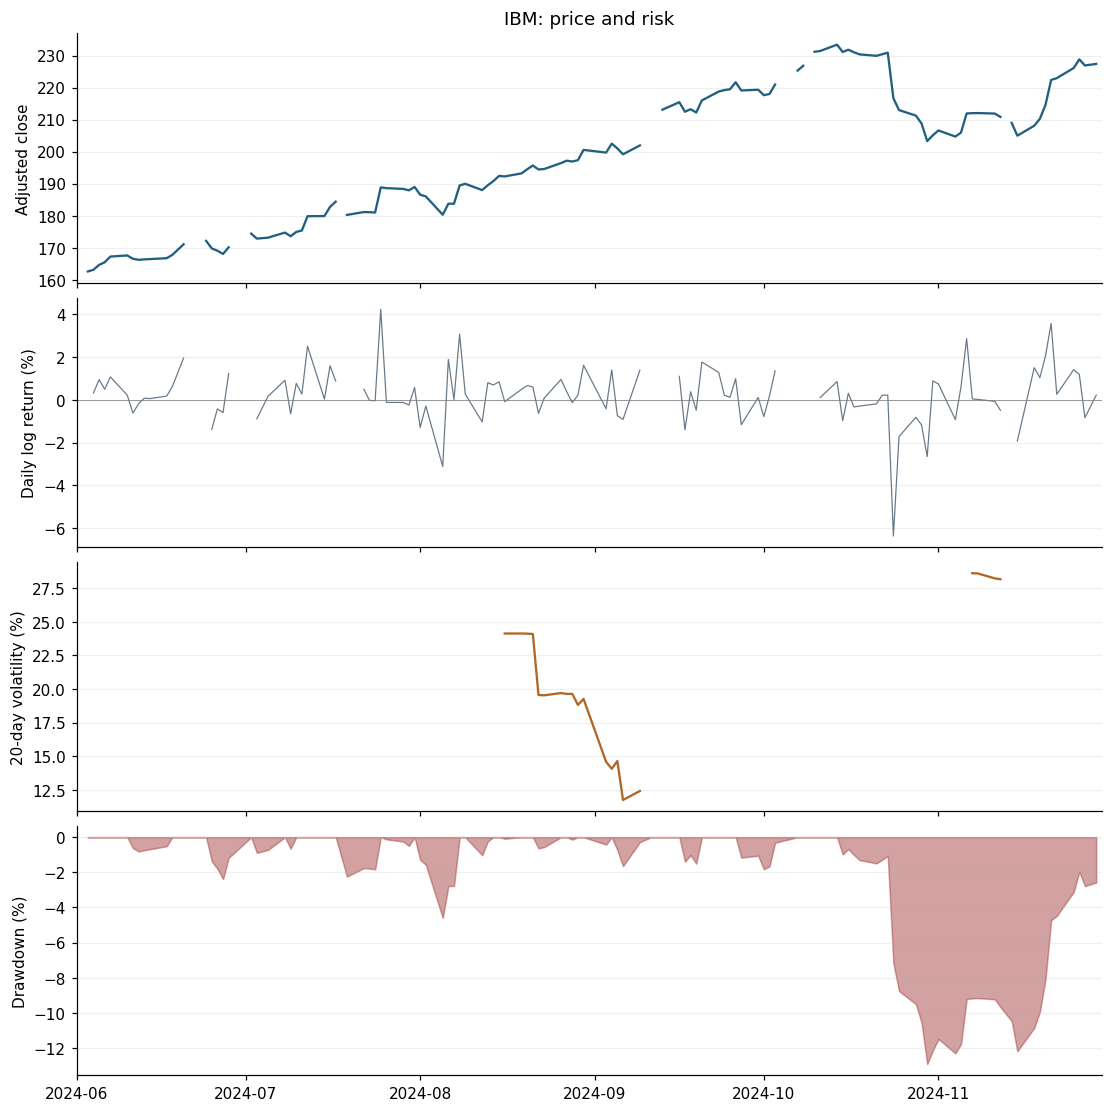

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True,
                         layout="constrained")
axes[0].plot(window.index, window.values, color="#215f80")
axes[0].set_ylabel("Adjusted close")
axes[0].set_title(f"{ticker}: price and risk")
axes[1].plot(daily.index, daily.values * 100, color="#677889", linewidth=0.8)
axes[1].axhline(0, color="grey", linewidth=0.5)
axes[1].set_ylabel("Daily log return (%)")
axes[2].plot(vol.index, vol.values * 100, color="#b06726")
axes[2].set_ylabel("20-day volatility (%)")
axes[3].fill_between(drawdown.index, drawdown.values * 100, 0,
                     color="#a64545", alpha=0.5)
axes[3].set_ylabel("Drawdown (%)")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
axes[-1].set_xlim(start, end)
plt.show()
plt.close(fig)

In [5]:
def finite_or_none(value):
    return float(value) if math.isfinite(value) else None


report_metrics = {
    "ticker": str(ticker),
    "avg_daily_return": finite_or_none(valid_returns.mean()),
    "avg_volatility": finite_or_none(vol.mean()),
    "max_drawdown": finite_or_none(drawdown.min()),
    "sharpe_ratio": finite_or_none(sharpe),
    "total_return": finite_or_none(total_return),
}
sb.glue("report_metrics", report_metrics)
report_metrics

{'ticker': 'IBM',
 'avg_daily_return': 0.0022349382427670184,
 'avg_volatility': 0.2068466899934987,
 'max_drawdown': -0.12903778596521287,
 'sharpe_ratio': 2.6363064639128786,
 'total_return': 0.3988435750753523}

These are descriptive historical results. The six-month window is short,
cleaning removes observations, and the date grid is inferred from this dataset.
No transaction costs, investable portfolio weights, or diversification benefits
are estimated. The batch summary compares individual stocks.